# Monthly Road-Segment Accident Prediction with Graph Neural Networks

## Introduction

Road traffic accidents impose substantial human and economic costs, estimated to cost an average of 2.7% of GDP in high-income countries (Wijnen & Stipdonk, 2016). They can be caused by pedestrians, drivers, vehicles, or the road environments. Although human behaviour is an important factor in crashes, road environments may also contribute by influencing the likelihood of driver errors and violations (Ahmad et al., 2021). Differences in road layout, traffic volume, surrounding land use and environmental conditions can contribute to differences in where crashes occur. Understanding the relationship between road characteristics and accidents may therefore help transport agencies identify road segments with elevated accident risk and prioritise them for safety assessment and improvements.

Machine learning offers a way to combine information about roads and their surroundings to predict where accidents are more likely to occur. Relevant information may include historical accident records, traffic volume and road characteristics. However, roads do not exist in isolation: connected road segments may share traffic flows, infrastructure and environmental conditions. This suggests that the relationships between roads may provide useful information for accident prediction. Graph-based methods provide a way to account for these connections when predicting accidents.

### Objectives

This project uses the ML4RoadSafety benchmark to study monthly accident prediction on road networks (Nippani et al., 2023). It aims to assess how well models predict monthly accidents on physical roads and whether additional information like network structure, additional road context, and previous accident records can improve those predictions.

### Research questions
> [!NOTE]
> Need to rewrite once the report is confirmed

1. **Network representation and learning:** How does the use of different graph machine learning methods improve the prediction of road traffic accident predictions?
2. **Road features and history**: To what extent do richer road characteristics and historical accident information improve monthly road-level accident prediction?

### Main contributions
> [!NOTE]
> Need to rewrite once the report is confirmed

- We compare an MLP and edge-aware GraphSAGE, with and without Node2Vec, under a shared physical-road target and chronological evaluation protocol.
- We develop an OSM enrichment and matching pipeline, audit its coverage, and assess its predictive value and feature reliance for GraphSAGE classification.
- We construct a past-only accident history representation and examine training-period evidence of temporal persistence, complemented by interactive spatial exploration.

These experiments adapt the benchmark's features, embeddings and target aggregation, so the reported scores constitute a modified reproduction rather than direct replications of the published results.


## Related Work

### Road Accidents Predictions

Existing work have explored the use of various methods to predict road accidents, ranging from statistical models, machine learning models, and deep learning models. Statistical learning approaches relate expected accident counts to road and traffic characteristics using count regression. Ma et al. (2017) applied negative-binomial and random-effects negative-binomial models to predict crash frequency on segments of a Chinese expressway using explanatory variables such as road geometry, and also explored the spatial and temporal correlation in the accidents data.

Traditional machine-learning approaches use algorithms like random forest and support vector machines to predict crashes (Guerra et al., 2022). Guerra et al. compared linear regression, Generalised Additve models, random forest, support vector machines, and artificial neural network on the traffic prediction task. They found that random forests produced the best results and the traffic volume given by annual average daily traffic (AADT), was a significant variable in predicting the crashes.

Deep-learning approaches can learn richer representations from information about roads to predict traffic accidents. Kashifi et al. (2023) developed a hybrid model combining convolutional neural networks, LSTMs and artificial neural networks for short-term crash prediction. They used information such as average speed, vehicle occupancy, weather data, temporal information, and crash data from the Paris road network, combining multiple different information to predict road traffic accidents.

Graph-based approaches are well suited for road accident prediction because roads form an interconnected network, and conditions on one road may be related to those on neighbouring roads. Graph models can represent these relationships explicitly and aggregate information between related road segments to improve predictions. Huang and Hooi (2022) developed TRAVEL, a graph neural network that incorporates road geometry and connectivity to predict accident occurrence and severity at intersections. Their model achieved better overall F1 and AUC scores than non-graph XGBoost and MLP baselines on their city datasets. Furthermore, their experiments also used other graph neural network (GNN) models such as Graph Convolutional Network (GCN), GraphSAGE, and ChebNet, which achieved better scores compared to the non-graph methods, supporting the argument that graph methods are well suited for road accident prediction tasks.

### Graph representation learning

Graph representation learning provides a framework for incorporating road-network structure into accident prediction. A road network can be represented as a graph whose nodes denote intersections and whose edges denote road segments. This representation allows a model to combine the attributes of a location with information from its connected roads and neighbouring intersections. Several methods differ in how they encode this structure and determine the contribution of neighbouring locations.

Node2Vec is a form of shallow graph learning that learns a vector representation for each node in the graph, which can be used for downstream predictive tasks (Grover & Leskovec, 2016). It is adapted from word2vec (Mikolov et al., 2013), where words are represented by nodes, while sentences are represented by biased random walk sequences along the graph. The biased random walk is obtained through a sampling process, controlled by two parameters, $p$ and $q$, which controls the probability of moving back to the previous node, and controls the probability of local or outward exploration. This provides more flexibility to the representation it can capture. Furthermore, it uses a skip-gram objective function, which helps to encourage nodes that are in the same random walk, and therefore likely to be close to one another, to have similar embeddings.

GraphSAGE learns node representations by performing uniform sampling around the node's neighbourhood, followed by aggregating features of the sampled nodes (Hamilton et al., 2017). Some examples of aggregation include using the mean, maximum, or using a Long Short Term Memory (LSTM) (Hochreiter & Schmidhuber, 1997). A non-linear transformation is applied to the concatenation of the node's features and its sampled neighbourhood, through multiple layers of aggregation. The multiple layers of aggregation helps to incorporate information from increasingly distant neighbours, allowing a node to capture more context and information beyond its neighbourhood.

However, GraphSAGE is an isotropic GNN. This means that the neighbours have no canonical direction labels and the different edges all same the same magnitude and weight regardless of their importance. GatedGCN (Bresson & Laurent, 2017) and Graph Transformers (Dwivedi & Bresson, 2020) are anisotropic GNNs which allow the contribution of neighbouring nodes to vary. GatedGCN uses learnable edge gates to control the contribution of neighbouring nodes during aggregation. The gates are learned from node and edge representations, allowing the model to adjust messages according to the relationship between connected nodes. Since the edge representations will get updated, GatedGCN can perform edge-aware message passing, which helps to improve tasks requiring edge predictions.

Graph Transformers (Dwivedi & Bresson, 2020) extend Transformers (Vaswani et al., 2017) to the graph domain by using the attention mechanism to assign weights to neighbouring nodes, restricting how nodes access and share information with one another. The attention mechanism assigns weights to these neighbours based on their representations, allowing their contributions to vary during aggregation. It also incorporates edge features into the attention mechanism, allowing attributes of the connections between nodes to influence the learned representations. In addition, Laplacian eigenvectors are used as node positional encoding to inject structural information to increase the expressivity of the models.

## Dataset and Exploratory Analysis

### Dataset, graph representation and prediction tasks

ML4RoadSafety is a public road-safety dataset constructed from official accident reports across eight US states, comprising more than nine million records in the full collection (Nippani et al., 2023). It links accident locations and dates to road networks derived from OpenStreetMap (OSM). Each state is represented as a directed graph, where nodes correspond to intersections and edges represent road segments. The dataset includes node-level structural and weather information, such as node degree, betweenness centrality, temperature and precipitation, as well as edge-level attributes, including road length, road category and AADT, where available. Accident records are associated with road-network edges and can be used to study monthly accident counts and occurrence. The dataset is available through [Harvard Dataverse](https://doi.org/10.7910/DVN/V71K5R). This study uses Delaware and Maryland for descriptive analysis and Delaware for predictive experiments; the full-collection accident total does not describe this subset.

For prediction, this study groups directed edges with the same unordered endpoints into a single **physical-road proxy**, summing their accident counts for each month. The original benchmark instead defines its prediction task at the directed-edge level (Nippani et al., 2023). Our message-passing graph remains directed. A **road-month** is one physical-road proxy observed in one month: classification predicts whether its count exceeds zero, while regression estimates the count. Zero-count roads are included in the target population. Endpoint-based grouping does not establish that every grouped pair is the same physical road and does not support direction-specific conclusions.

Our feature construction, structural embedding implementation, physical-road aggregation and evaluation population adapt the original benchmark. These methodological changes make the experiments a modified reproduction, so their scores are not direct replications of the published benchmark results.


In [1]:
# Use Google Drive in Colab, or the local repository otherwise.
import os
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/gdrive')
    # Set this to the repository folder containing src/ and data/ in Drive.
    PROJECT_DIR = Path(os.environ.get(
        'CS5284_PROJECT_DIR', '/content/gdrive/MyDrive/cs5284_project'))
else:
    configured = os.environ.get('CS5284_PROJECT_DIR')
    if configured:
        PROJECT_DIR = Path(configured).expanduser()
    else:
        PROJECT_DIR = next(
            (p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'src' / 'eda.py').is_file()), None)
        if PROJECT_DIR is None:
            raise FileNotFoundError('Open this notebook inside the repository or set CS5284_PROJECT_DIR.')

PROJECT_DIR = PROJECT_DIR.resolve()
if not (PROJECT_DIR / 'src' / 'eda.py').is_file():
    raise FileNotFoundError(f'Place the repository (including src/eda.py) in {PROJECT_DIR}, or update PROJECT_DIR.')
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
DATA_DIR = Path(os.environ.get('CS5284_DATA_DIR', str(PROJECT_DIR / 'data'))).expanduser().resolve()
os.environ['CS5284_PROJECT_DIR'] = str(PROJECT_DIR)
os.environ['CS5284_DATA_DIR'] = str(DATA_DIR)
print(f'Project: {PROJECT_DIR}')
print(f'Data: {DATA_DIR}')


In [2]:
from IPython.display import display
import matplotlib.pyplot as plt
from src.reporting import apply_report_style
apply_report_style()
from src.eda import (
    load_data, dataset_summary, split_summary, audit_data,
    accident_distribution, concentration, historical_persistence,
    plot_monthly_accidents, plot_risk_profile,
)

# Select ('DE',) for a Delaware-only run. Data must already be extracted.
STATES = ('DE', 'MD')
data = load_data(DATA_DIR, states=STATES)
summary = dataset_summary(data)
audit = audit_data(data)  # Streams node CSVs once; reused below.
distribution = accident_distribution(data)
concentration_table = concentration(data)


In [3]:
display(summary[['Period', 'Nodes', 'Directed edges', 'Physical roads',
                 'Accidents/month', 'Traffic coverage (%)']].style.format({
    'Nodes': '{:,.0f}', 'Directed edges': '{:,.0f}', 'Physical roads': '{:,.0f}',
    'Accidents/month': '{:,.0f}', 'Traffic coverage (%)': '{:.2f}',
}).set_caption('Table 1. Dataset scope; traffic coverage is the share of physical roads with a finite AADT observation in any supplied year.'))


,Period,Nodes,Directed edges,Physical roads,Accidents/month,Traffic coverage (%)
State,,,,,,
Delaware,2009-01 to 2022-09,"49,023","116,196","65,252","2,777",3.16
Maryland,2015-01 to 2022-12,"250,565","580,526","317,281","9,149",1.40


### Data quality and chronological coverage

Delaware covers January 2009–September 2022 (165 months), while Maryland covers January 2015–December 2022 (96 months). October 2022 is excluded for Delaware because monthly node features are unavailable and the month is treated as incomplete.

Data checks cover label validity, duplicate directed road-month records, graph membership, node ordering, feature dimensions and missing observations. The audit identifies no duplicate accident records or invalid counts, and all accident records map to graph edges. Roads with missing attributes are retained. Monthly weather and traffic are imputed and standardised using training-year statistics, with missingness indicators; traffic observations are carried forward only from earlier years. Static-graph scaling is described separately in Methodology.

The chronological splits follow Nippani et al. (2023). Full-period plots describe temporal coverage and distributional changes; neighbour-risk and history associations use training years. This distinction prevents descriptive use of the full period from being interpreted as held-out predictive evidence. Forecast evaluation requires inputs to respect the information available before each target observation (Hyndman & Athanasopoulos, 2021, Section 5.10).


In [4]:
display(split_summary(data).style.set_caption('Table 2. Chronological splits and observed month availability.'))

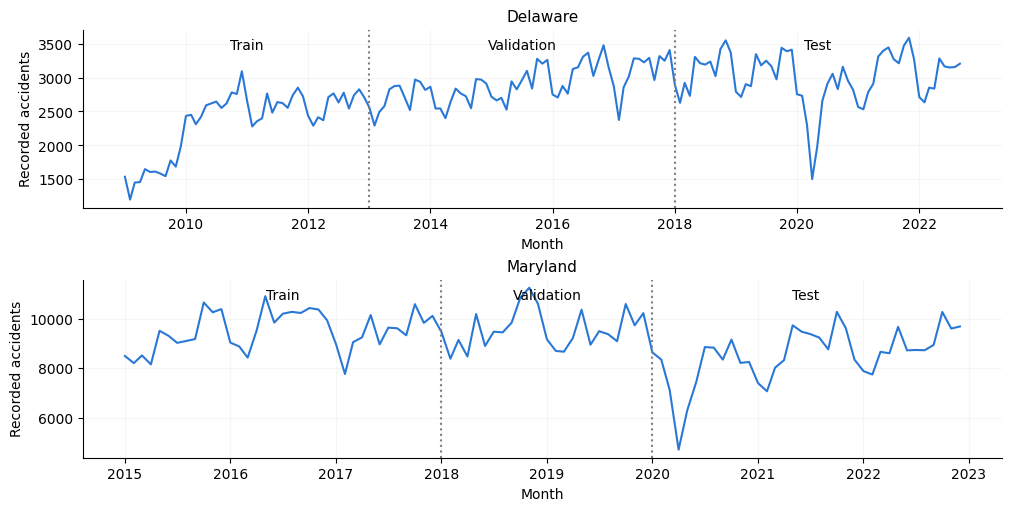

In [5]:
fig = plot_monthly_accidents(data)
plt.show()


*Figure 1. Monthly recorded accidents and chronological split boundaries.* Both states show a decline around early 2020 followed by recovery. The timing coincides with the national decline in road travel reported by the Federal Highway Administration (2021), although this correspondence does not identify the cause of the state-level changes. The decline falls within the test period and illustrates temporal distribution shift.

### Accident sparsity and concentration

Zero-count road-months account for **96.52%** of Delaware's population and **97.61%** of Maryland's. Consequently, low MAE alone can favour predictions near zero. Precision-recall evaluation complements AUROC by focusing on the rare positive class (Saito & Rehmsmeier, 2015), while top-risk metrics assess prioritisation.

The highest-count 10% of roads account retrospectively for **70.6%** and **73.6%** of accidents, respectively. This concentration motivates road-level prioritisation. Because the ranking uses observed counts across the full period, it describes concentration rather than forecast performance.


,Road-months,Zero accidents (%),Mean count
State,,,
Delaware,"10,766,580",96.52,0.0426
Maryland,"30,458,976",97.61,0.0288


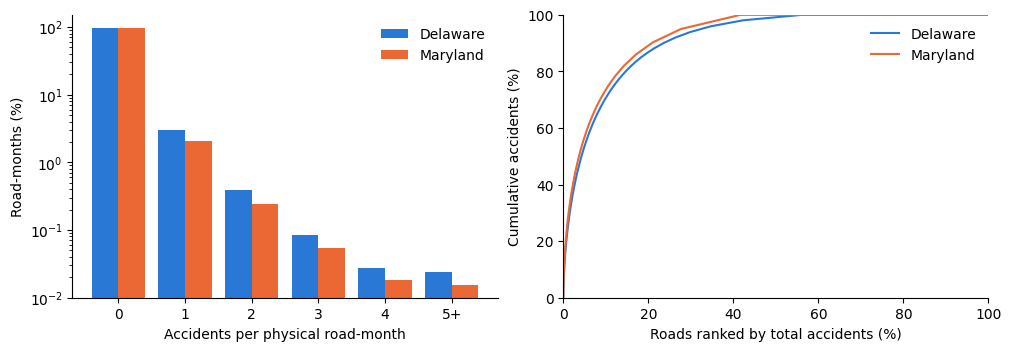

In [6]:
display(distribution[['Road-months', 'Zero accidents (%)', 'Mean count']].style.format({
    'Road-months': '{:,.0f}', 'Zero accidents (%)': '{:.2f}', 'Mean count': '{:.4f}',
}))
fig = plot_risk_profile(data)
plt.show()


*Figure 2. Accident-count distribution and retrospective concentration across physical roads.* The logarithmic axis makes infrequent positive counts visible. Training-period neighbour-risk correlations are 0.538 in Delaware and 0.556 in Maryland. These associations motivate investigation of connected-road information, while shared traffic exposure and road characteristics provide alternative explanations for the spatial dependence.


### Spatial exploration of training accidents

Interactive map A displays recorded accident concentrations during the training years: **2009–2012 in Delaware** and **2015–2017 in Maryland**. State, month and period controls support inspection of recurring locations and surrounding network structure. Counts are unadjusted for exposure and should not be interpreted as causal safety effects.

The display combines a fixed random background with roads having high training-period accident totals. Summary cards cover the full road population, while the displayed subset supports detailed inspection. Straight endpoint connections approximate road geometry. Validation and test labels do not determine which roads are displayed.


In [7]:
from src.visualization.risk_map import show_risk_map, list_prediction_exports

SHOW_INTERACTIVE_MAPS = True
MAP_MAX_ROADS = 1500  # Display budget per state; summary cards still cover all roads.
MAP_OUTPUT_DIR = PROJECT_DIR / 'results' / 'visualizations'
if SHOW_INTERACTIVE_MAPS:
    eda_map_path = show_risk_map(
        PROJECT_DIR, max_roads=MAP_MAX_ROADS, mode='eda',
        data_dir=DATA_DIR, results_dir=PROJECT_DIR / 'results', state_codes=STATES,
        output_path=MAP_OUTPUT_DIR / 'road_safety_training_eda.html',
    )


<iframe title="Road Safety Explorer" width="100%" height="860" style="border:0" srcdoc="<!doctype html><html><head><meta charset="utf-8">
<script src="https://cdn.plot.ly/plotly-3.1.0.min.js"></script>
<style>
*{box-sizing:border-box}body{margin:0;background:#f3f6fa;color:#152238;font:14px system-ui,sans-serif}
header{height:86px;background:#101e34;color:white;padding:20px 26px;display:flex;justify-content:space-between;align-items:center}
h1{font-size:23px;margin:0;letter-spacing:-.5px}header p{margin:5px 0;color:#aebed3;font-size:12px}.badge{color:#85e0ce;border:1px solid #355469;padding:7px 12px;border-radius:20px;font-size:11px}
main{display:grid;grid-template-columns:250px 1fr;gap:16px;padding:18px}aside,.card{background:white;border:1px solid #e1e7ef;border-radius:12px}
aside{padding:20px;height:700px}label{display:block;font-size:11px;text-transform:uppercase;letter-spacing:1px;color:#64748b;margin:22px 0 8px}label:first-child{margin-top:0}
select{width:100%;padding:10px 8px;border:1px solid #d8e0ec;border-radius:7px;background:white;color:#1e293b;font-size:12px}button{border:1px solid #d8e0ec;background:white;border-radius:7px;padding:9px;cursor:pointer;color:#334155}
.nav{display:flex;gap:8px;margin-top:9px}.nav button{flex:1}.note{font-size:11px;color:#64748b;line-height:1.7;margin-top:24px}.stats{display:grid;grid-template-columns:repeat(3,1fr);gap:12px;margin-bottom:12px}.stat{padding:15px 18px}.stat span{display:block;color:#64748b;font-size:11px}.stat strong{display:block;font-size:24px;margin-top:5px;font-weight:650}.maphead{display:flex;justify-content:space-between;padding:16px 18px;border-bottom:1px solid #edf1f6}.maphead b{font-size:15px}.maphead span{font-size:11px;color:#64748b}#map{height:520px}.foot{padding:10px 18px;font-size:11px;color:#64748b;line-height:1.6}#status{color:#b45309;padding-top:8px} @media(max-width:750px){main{grid-template-columns:1fr}aside{height:auto}.stats{gap:5px}.stat strong{font-size:18px}}
</style></head><body>
<header><div><h1 id="appTitle">Road Safety Explorer</h1><p id="appSubtitle">Historical accidents and baseline model predictions</p></div><div class="badge">CS5284 · GROUP 01</div></header>
<main><aside><label>State</label><select id="state"></select><label>Basemap</label><select id="basemap"><option value="carto-darkmatter">Dark · high contrast</option><option value="carto-positron">Light · minimal</option><option value="open-street-map">Street detail</option></select><label>Map layer</label><select id="view"><option value="observed">Recorded accidents</option><option value="predicted">Model prediction</option><option value="error">Prediction error</option></select><label>Model / seed</label><select id="model"></select><label>Aggregation</label><select id="aggregation"><option value="monthly">Monthly</option><option value="quarterly">Quarterly</option><option value="yearly">Yearly</option></select><label>Period</label><select id="month"></select><div class="nav"><button id="prev">← Previous</button><button id="next">Next →</button></div><label>Road details</label><div id="details" class="note">Hover over a road to inspect its values.</div><div class="note">Historical layers cover the retained data period. Predictions cover exported test months only. Opposite directions are combined into physical-road proxies.</div></aside>
<section><div class="stats"><div class="card stat"><span>RECORDED ACCIDENTS</span><strong id="total">—</strong></div><div class="card stat"><span>ROADS WITH ACCIDENTS</span><strong id="positive">—</strong></div><div class="card stat"><span id="thirdLabel">MODEL</span><strong id="third">—</strong></div></div><div class="card"><div class="maphead"><b id="title">Accident map</b><span id="period"></span></div><div id="map"></div><div class="foot" id="foot"></div></div><div id="status"></div></section></main>
<script>
const DATA={"DE":{"dates":["2009-01","2009-02","2009-03","2009-04","2009-05","2009-06","2009-07","2009-08","2009-09","2009-10","2009-11","2009

*Interactive map A. Spatial distribution of training-period accidents.* The standalone HTML accompanying the notebook supports interactive exploration; map rendering requires internet access for external plotting resources and basemap tiles.


### Feature availability

Weather missingness varies by variable and state, ranging from **38.8–67.7%** in Delaware and **61.5–74.3%** in Maryland, with coverage also changing over time. Only **3.16%** and **1.40%** of physical roads, respectively, have a finite AADT observation in any supplied year. These gaps motivate missingness indicators and limit exposure-adjusted interpretation of feature associations.


In [8]:
weather_missing = audit['weather_missingness']['Missing (%)'].unstack('State')
display(weather_missing.style.format('{:.1f}').set_caption('Table 3. Missing weather observations (%), across all usable node-months.'))
# Inspect audit['checks'] for the complete integrity report.


State,Delaware,Maryland
Feature,,
Air pressure,67.7,74.3
Maximum temperature,38.8,61.5
Mean temperature,42.7,61.7
Minimum temperature,38.8,61.5
Precipitation,50.5,69.0
Wind speed,46.6,69.7


## Methodology

### Baseline models and road-level prediction

We compare an MLP with the benchmark's edge-aware GraphSAGE adaptation (Hamilton et al., 2017; Nippani et al., 2023), each with and without fixed Node2Vec embeddings (Grover & Leskovec, 2016). GraphSAGE produces intersection representations through message passing; the MLP omits this graph encoder. A shared road-level predictor combines endpoint representations with road attributes. Monthly inputs include weather and available traffic; structural inputs include coordinates, degree and approximate betweenness. Classification and regression use separate task-specific models.


### Past-only accident-history representation

The history representation comprises six own-road features: last-month count, 3/6/12-month means, twelve-month lag and twelve-month nonzero fraction. Three neighbourhood features describe last-month and three-month mean counts on adjacent roads and the number of neighbours. A coverage indicator records the number of usable prior months. Every dynamic input for target month T ends at T−1. Incomplete windows remain missing, and absent source months are not automatically treated as accident-free.

Opposite-direction counts are summed **before** history construction, and the resulting physical-road features are broadcast to both message-passing directions. Neighbours are distinct physical connections sharing an endpoint, excluding the target road and its reverse. This aligns historical inputs with the prediction target and prevents the unused label direction from being treated as an independent accident-free road.

The descriptive history analysis uses a twelve-month warm-up and is restricted to **2010–2012 Delaware training targets**, leaving 36 eligible months. This past-only cutoff follows the temporal evaluation principle described by Hyndman and Athanasopoulos (2021, Section 5.10). The analysis examines associations with subsequent counts; it does not estimate the incremental performance of a history-enhanced predictive model.


## Experimental Setup

### Training and model selection

Baseline experiments cross **MLP/GraphSAGE × classification/regression × Node2Vec off/on**, giving eight Delaware configurations. Each uses three model seeds (0, 1 and 2), 100 epochs, two width-256 layers, zero dropout and Adam at learning rate 0.001 (Kingma & Ba, 2015). Training samples positive and zero-count roads at a 1:1 ratio; validation and testing include all physical roads. Classification minimises binary cross-entropy. Regression minimises MAE, with negative count predictions clipped to zero at evaluation.

Validation is performed every five epochs and at the final epoch. The checkpoint with highest validation AUROC for classification or lowest validation MAE for regression is evaluated on test. This is checkpoint selection, without early termination of training. Chronological splits are shown in Table 2.

### Evaluation metrics

Primary AUROC is calculated monthly and averaged using positive-road counts as weights. **AP** denotes scikit-learn average precision, rather than trapezoidal area under the precision-recall curve (scikit-learn developers, n.d.). Top-1% precision and recall assess prioritisation. Subgroup AUROC is pooled across road-months and distinguished from the primary monthly metric. Reported spreads are population standard deviations (`ddof=0`) across the three model seeds, rather than confidence intervals.


## Results and Discussion

### Baseline comparisons

Tables 6–7 compare the eight Delaware configurations across three seeds. Classification is assessed primarily by AUROC and count regression by MAE. Each configuration is reported separately; test performance is not used to select among repeated runs.


In [13]:
from src.reporting import load_training_results, format_training_results, plot_training_history

RESULTS_DIR = PROJECT_DIR / 'results'
training_results = load_training_results(RESULTS_DIR)
if training_results.empty:
    print('No completed ordinary training results are available in', RESULTS_DIR)
else:
    display(format_training_results(training_results, 'classification').style.hide(axis='index').set_caption(
        'Table 6. Classification performance: mean ± SD across model seeds. AP is average precision.'))
    display(format_training_results(training_results, 'regression').style.hide(axis='index').set_caption(
        'Table 7. Count-regression performance: MAE is primary; AUROC evaluates ranking by predicted counts.'))
    # Provenance remains available for inspection alongside each run.
    training_provenance = training_results[['Run', 'Source commit', 'Dirty checkout']]


State,Model,Node2Vec,Seeds,AUROC,AP,Run
DE,graphsage,With,3,0.8743 ± 0.0003,0.2627 ± 0.0013,DE_graphsage_classification_n2v
DE,graphsage,Without,3,0.8461 ± 0.0037,0.2134 ± 0.0024,DE_graphsage_classification_no_n2v
DE,mlp,With,3,0.8780 ± 0.0002,0.2788 ± 0.0016,DE_mlp_classification_n2v
DE,mlp,Without,3,0.8449 ± 0.0008,0.2112 ± 0.0013,DE_mlp_classification_no_n2v


State,Model,Node2Vec,Seeds,MAE,AUROC,Run
DE,graphsage,With,3,0.2070 ± 0.0038,0.8569 ± 0.0025,DE_graphsage_regression_n2v
DE,graphsage,Without,3,0.2316 ± 0.0048,0.8357 ± 0.0013,DE_graphsage_regression_no_n2v
DE,mlp,With,3,0.2201 ± 0.0040,0.8648 ± 0.0011,DE_mlp_regression_n2v
DE,mlp,Without,3,0.2506 ± 0.0022,0.8161 ± 0.0028,DE_mlp_regression_no_n2v


Node2Vec improves both baseline architectures in the Delaware experiments. With Node2Vec, the MLP achieves higher classification AUROC (**0.8780**) than GraphSAGE (**0.8743**), while GraphSAGE achieves lower count-regression MAE (**0.2070**) than the MLP (**0.2201**). The benefit of learned message passing therefore depends on the prediction task. Structural embeddings remain useful even without a learned graph encoder, and the graph model is not uniformly stronger.


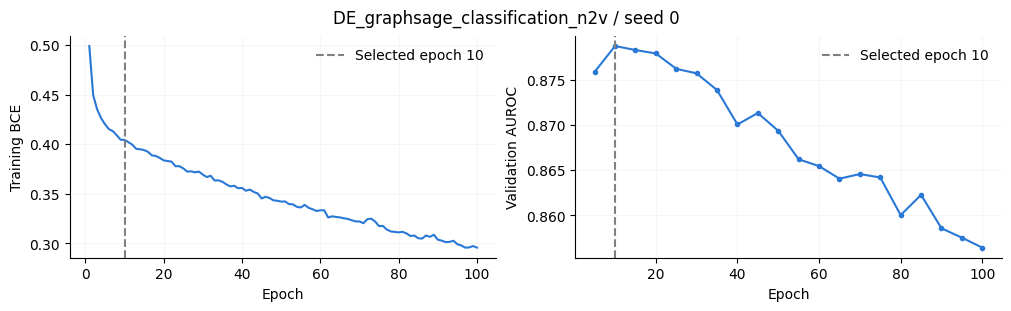

In [14]:
HISTORY_RUN = 'DE_graphsage_classification_n2v'
HISTORY_SEED = 0
if (RESULTS_DIR / HISTORY_RUN / f'seed{HISTORY_SEED}_history.csv').exists():
    fig = plot_training_history(RESULTS_DIR, HISTORY_RUN, HISTORY_SEED)
    plt.show()
else:
    print('Training history unavailable for', HISTORY_RUN)


*Figure 3. Training loss and validation AUROC for GraphSAGE with Node2Vec, seed 0.* The marked checkpoint is selected by validation performance. Training loss uses sampled roads, whereas validation covers all roads; their magnitudes are not directly comparable. Test performance is reserved for final evaluation.


### Historical persistence of accident incidence

Table 10 relates next-month accident incidence to strictly prior three-month accident totals on physical roads. It uses only **2010–2012 Delaware training targets** after the twelve-month warm-up. History construction is checked for target alignment and invariance to changes in target-month and future labels, ensuring that the displayed association does not depend on those labels entering the inputs.

The probability of a next-month accident increases from **2.04%** following zero accidents in the previous three months to **75.80%** following six or more. Mean next-month count increases from **0.0221** to **2.1551** across the same categories. This gradient demonstrates temporal persistence in the training population. It may reflect persistent exposure, road characteristics and other unobserved differences between roads, rather than a causal effect of previous accidents.


In [17]:
import json
from src.history.integration import PhysicalHistory, history_readiness, training_risk_by_history
from src.history.features import run_self_checks

history_data = PhysicalHistory.load(DATA_DIR / 'DE')
history_branch_manifest = json.loads((PROJECT_DIR / 'reports/history_branch_manifest.json').read_text())
history_source_match = (history_data.source_audit['source_sha256'] == history_branch_manifest['source_sha256'])
print('Local accident/graph files match branch exports:', history_source_match)
print('Past-only source self-checks:', run_self_checks())
history_coverage = history_readiness(history_data)  # 36/60/57 with the matched warm-up.
display(training_risk_by_history(history_data).style.format({
    'Road-months': '{:,.0f}', 'Next-month accident probability (%)': '{:.2f}',
    'Mean next-month count': '{:.4f}',
}).hide(axis='index').set_caption(
    'Table 10. Subsequent accident incidence by strictly prior three-month physical-road history (2010–2012 training targets).'))


Prior 3-month accidents,Road-months,Next-month accident probability (%),Mean next-month count
0,"2,163,898",2.04,0.0221
1,"136,650",12.52,0.1475
2,"30,091",24.98,0.3232
3–5,"15,776",42.23,0.6418
6+,"2,657",75.80,2.1551


The history analysis is exploratory: its outcome is an association with subsequent incidence, rather than a measured gain in held-out AUROC or MAE. A predictive comparison would need to account for the shorter training population introduced by the twelve-month warm-up and the availability of accident reports at each forecast origin.


## Enriching the Inputs

The benchmark describes each road by little more than its type and length, and it uses past accidents only as training labels. This section adds two kinds of information to the baseline above: what a road *is like*, taken from OpenStreetMap, and what has *happened on it before*, its accident history. Each is tested as an addition to the same baseline, under the same chronological evaluation.

### OpenStreetMap Road Features

#### Motivation

Crash risk depends on the road environment, including how fast traffic moves, how many lanes there are, how junctions are controlled and how much activity surrounds the road (Ahmad et al., 2021). The benchmark's road input contains almost none of this. Each road carries road-type indicators and its length, plus annual traffic volume (AADT) where it was observed, which is only 3.16% of Delaware's physical roads. The benchmark's graph was itself built from OpenStreetMap (OSM), yet the richer tags that OSM holds for many roads were left out. We therefore built a pipeline that extracts these attributes from a dated OSM snapshot and attaches them to the benchmark's roads. We then asked two questions: do they improve our re-implementation of the paper's GraphSAGE classifier, and which attributes go with more or fewer accidents? Figure O1 summarises the pipeline.

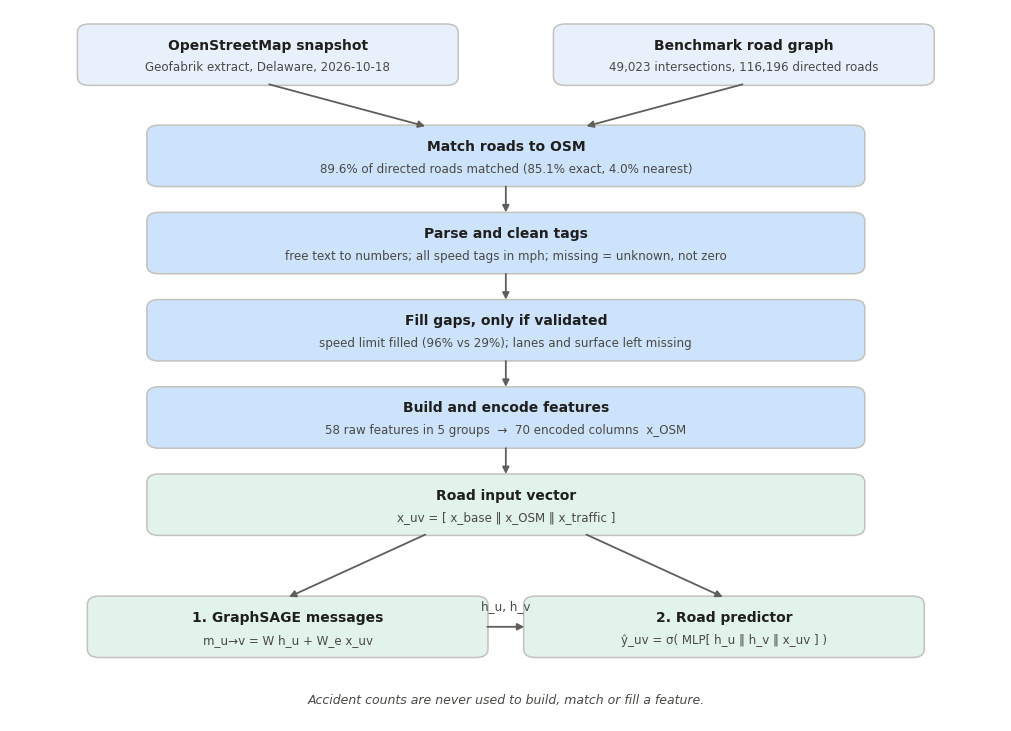

In [15]:
from src.osm.report import (
    load_osm_results, osm_comparison_table, permutation_table,
    plot_osm_comparison, plot_osm_pipeline,
)

fig = plot_osm_pipeline()
plt.show()

*Figure O1. The OSM pipeline for Delaware. The snapshot and the benchmark graph are matched road by road; tags are parsed and cleaned, validated gaps are filled, and the encoded vector $x^{\mathrm{OSM}}$ is appended to each road's input. GraphSAGE uses that input twice: in its messages and in the road predictor. Accident counts never enter feature construction.*

#### Method

**Source and matching.** We used a Geofabrik extract of Delaware dated 18 October 2026 (Geofabrik, n.d.) and read it with OSMnx (Boeing, 2025) into three tables: road pieces with their tags, tagged control points (signals, stop and give-way signs, crossings, traffic calming) and points of interest. Each benchmark intersection was matched to the OSM node with the same identifier if their coordinates agreed within 25 m, and otherwise to the nearest OSM node within 20 m. Each directed benchmark road was then matched in three tiers: the same node pair, the reversed pair, or the nearest OSM road whose midpoint lies within 30 m and whose length is 0.6–1.6 times the benchmark length. These thresholds are our own choices. Unmatched roads stay in the prediction population with an `unmatched` flag. Table O1 summarises the outcome.

| Step | Delaware |
|---|---|
| Directed benchmark roads | 116,196 |
| Matched to an OSM road | **89.6%** of roads (84.3% of accidents) |
| … by exact / reverse / nearest pair | 85.1% / 0.5% / 4.0% of roads |
| Not matched | 10.4% of roads (15.7% of accidents) |
| OSM speed tags with an explicit unit | **19,504 of 19,504** (all `mph`) |
| OSM lane tags parsed to a number | 18,456 of 18,456 |
| Gap-fill: speed limit | 96% within 5 mph vs 29% for the state-wide value: **filled** |
| Gap-fill: lanes | 73% vs 64%, but est. 55% on truly missing roads (< 60%): **not filled** |
| Gap-fill: surface | 97% vs 95% (gain < 5 points): **not filled** |

*Table O1. Matching and cleaning outcomes for Delaware. Road shares are of directed benchmark roads; tag counts are of OSM road pieces. Source: `osm_features_and_eda.ipynb`, Stages 7.2, 9.1 and 10.1.*

**Cleaning.** OSM tags are free text, so each tag was parsed by explicit rules: a list keeps its highest value (`["25 mph", "35 mph"]` becomes 35), word-only values such as `none` become missing, and a road whose OSM pieces disagree on surface becomes `mixed`. OSM defines a speed limit without a unit as km/h (OpenStreetMap contributors, n.d.), so reading such values as mph would be wrong. We counted how often this case arises: every one of Delaware's 19,504 speed tags carries an explicit `mph`, so the case never occurs. A missing tag is treated as *unknown*, never as zero, because OSM coverage is selective. Speed limits are known on 13.9% of roads, yet those roads carry 43.8% of accidents, because major roads are mapped more thoroughly. Matching every unmatched road would raise speed-limit coverage by at most 2.0 points, so the gaps come from unmapped tags rather than from failed matches.

Gaps in speed limit, lanes and surface were filled only if a method passed a validation gate. We hid known values in five folds and predicted them from road type alone, or from same-type neighbouring roads. A method had to beat the state-wide most common value by at least 5 percentage points and reach 60% accuracy. That threshold had to hold not only on the hidden values but also on an estimate for the truly missing roads, which differ from tagged ones. Speed counted as correct within 5 mph; lanes and surface had to match exactly. Only speed limit passed. Estimated values are kept in separate columns with an `is_estimated` flag, and the experiment below uses the raw tags with missing flags, so **no estimated value enters the reported model**.

**Features.** Table O2 lists the five feature groups. When OSMnx simplifies the road graph, most tagged control points stop being nodes: 84% of stop signs and 99.6% of crossings in Delaware. We recovered all of them as mid-block counts within 15 m of each road. Nearby places count seven kinds of point (schools, bus stops, food outlets, bars, parking, crossings and signals) within 100, 250, 500 and 1,000 m of the road midpoint, and add the distance to the nearest of each kind. Road shape is the benchmark length divided by the straight-line distance between the road's endpoints.

| Group | Contents | Raw columns | Encoded columns | Roads with a value |
|---|---|---|---|---|
| Road character | speed limit, lanes, surface, bridge, tunnel | 5 | 14 | speed 13.9%, lanes 12.6%, surface 17.3% |
| Intersection control | signal / stop / crossing at each end, roundabout; mid-block signals, stops, give-way, crossings, traffic calming | 14 | 12 | 89.6% (matched roads) |
| Cycle, pedestrian, lighting | cycleway, sidewalk, street lighting | 3 | 6 | 0.6–2.4% |
| Nearby places | 7 kinds × (counts at 4 radii + nearest distance) | 35 | 35 | 100% |
| Road shape | sinuosity | 1 | 2 | 99.4% |
| Unmatched flag | road has no OSM match | – | 1 | 100% |
| **Total** | | **58** | **70** | |

*Table O2. OSM feature groups for Delaware. Encoded columns add one-hot surface categories and missing flags and drop constant columns. Coverage is the share of the 116,196 directed roads with a value. Sources: `osm_features_and_eda.ipynb` Stages 7.1 and 13; encoded columns from `results/osm/*/run_metadata.json`.*

**Encoding and model.** Counts and distances were log1p-transformed. Lanes were clipped at 8 and sinuosity to [1, 5], surface was one-hot encoded with rare categories pooled, and every column with gaps received a missing flag. Static OSM columns were standardised over all graph edges and clipped to ±10. This yields 70 columns $x^{\mathrm{OSM}}_{uv}$ for each directed road $(u, v)$, appended to the baseline's static road features:

$$x_{uv,t} = \big[\, x^{\mathrm{base}}_{uv} \,\|\, x^{\mathrm{OSM}}_{uv} \,\|\, x^{\mathrm{traffic}}_{uv,t} \,\big].$$

In the paper's edge-aware GraphSAGE (Hamilton et al., 2017; Nippani et al., 2023) this vector is used twice. First, it is part of every message an intersection receives:

$$\tilde h^{(\ell+1)}_v = \frac{1}{d_v + 1}\Big[\, W^{(\ell)} h^{(\ell)}_v + \sum_{u \in \mathcal{N}(v)} \big( W^{(\ell)} h^{(\ell)}_u + W^{(\ell)}_e\, x_{uv,t} \big) \Big], \qquad h^{(\ell+1)}_v = \mathrm{BN}\!\left( \frac{\tilde h^{(\ell+1)}_v}{\lVert \tilde h^{(\ell+1)}_v \rVert_2} \right),$$

with a ReLU between the two layers. Here $h^{(0)}_v$ holds the node features (coordinates, degree, betweenness, weather and, when used, Node2Vec), and biases are omitted. Second, it is passed directly to the road predictor:

$$\hat p_{uv,t} = \sigma\Big( \mathrm{MLP}\big[\, h^{(2)}_u \,\|\, h^{(2)}_v \,\|\, x_{uv,t} \,\big] \Big).$$

An intersection's representation therefore reflects the OSM attributes of the roads around it, as well as those of the road being scored. The architecture, loss, sampling and checkpoint selection are unchanged from the baseline.

**Experimental design.** We crossed OSM off/on with Node2Vec off/on for Delaware GraphSAGE classification, with three seeds each and the baseline's training protocol. The with-Node2Vec control was retrained through the same driver without OSM columns and reproduces the committed baseline (0.8743). The without-Node2Vec control is the committed baseline run, not retrained. The four runs therefore differ only in their inputs. To measure which inputs the fitted model *relies on*, we shuffled one feature group across roads at test time and recorded the AUROC drop, averaged over three repeats and the three seeds (Fisher et al., 2019). This does not retrain the model, so it measures reliance rather than the gain from adding a group.

#### Results

Adding all OSM groups raises test AUROC from **0.8461 to 0.8713 without Node2Vec (+0.0252)** and from **0.8743 to 0.8772 with Node2Vec (+0.0029)** (Table O3, Figure O2). All three seeds improve in both settings, and each gain exceeds its control's seed spread (SD 0.0037 and 0.0003). The ranking metrics, which matter when roads are prioritised for inspection, improve as well. Without Node2Vec, average precision rises from 0.213 to 0.255. Precision among the 1% of roads ranked riskiest each month rises from 0.392 to **0.445**, which means about five more true accident roads for every hundred flagged.

In [16]:
osm_results = load_osm_results(PROJECT_DIR)
display(osm_comparison_table(osm_results).style.format({'Change': '{:+.4f}'}).set_caption(
    'Table O3. Delaware GraphSAGE classification, test set: mean ± SD (ddof=0) over three seeds. '
    'Seeds improved pairs runs by seed number.'))

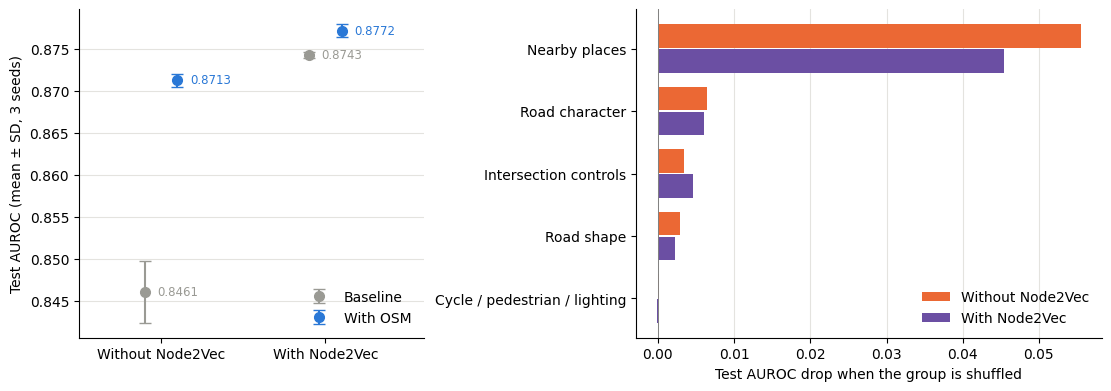

In [17]:
fig = plot_osm_comparison(osm_results)
plt.show()

*Figure O2. Left: test AUROC with and without OSM features, for both Node2Vec settings (mean ± SD over three seeds; the axis is zoomed). Right: test AUROC lost when one OSM group is shuffled across roads; larger means the model relies on it more.*

#### Analysis

**The model relies mainly on nearby places.** Shuffling the nearby-places group costs 0.0555 AUROC without Node2Vec and 0.0454 with it, which is more than half the cost of shuffling all OSM columns (0.0908 and 0.0791). Road character, intersection control and road shape each cost less than 0.007, and the cycle, pedestrian and lighting tags cost nothing. The ranking follows coverage. Nearby places are known for every road, whereas the most interpretable tags (speed, lanes, lighting) are known for only 0.6–14% of roads, so a model can learn little from them. Nearby-place counts also act as a stand-in for traffic exposure: signals, food outlets and parking mark busy built-up areas, where more traffic means more accidents. Measured traffic shows no reliance at all because AADT is observed on at most 1.1% of directed roads in any year, so the column is almost constant. Permutation scores describe what this fitted model uses, not what a group would add on its own: correlated groups can stand in for each other.

**The gain is almost nine times larger without Node2Vec.** Node2Vec alone raises the baseline by +0.0282 (0.8461 → 0.8743). OSM alone recovers +0.0252 of this, about 89%, from interpretable attributes rather than a learned embedding. Once Node2Vec is present, OSM adds only +0.0029. The two largely encode the same thing: a road's position in the network implies much about how built-up its surroundings are, which is exactly what the nearby-places group measures. We tried to test this directly with a spatially blocked ridge probe that predicts the top ten principal components of the Node2Vec embedding from road features. The result was inconclusive. Weighted held-out $R^2$ was −0.026 from the OSM features and −0.000 from the baseline road features, and those ten components hold only 10.8% of the embedding's variance. The overlap claim therefore rests on the 2×2 pattern, not on a reconstruction of the embedding.

**The gain is consistent over time, and larger on motorways.** With Node2Vec, the monthly AUROC change is positive in **all 57 test months** (mean +0.0029; whole-month bootstrap interval [0.0026, 0.0031], which ignores serial dependence). Pooled over road-months, the gain is larger on motorways (+0.0142, 706 roads) than on residential roads (+0.0029, 44,294 roads). This fits the denser tagging of major roads, but accident prevalence also differs between the two groups. Both analyses come from `osm_baseline_comparison.ipynb` (§10–11), because they need the prediction tensors, which are too large to commit.

**OSM narrows the gap between models but does not change their ranking.** With OSM and Node2Vec, GraphSAGE reaches 0.8772, still just below the MLP with Node2Vec (0.8780). We did not add OSM features to the MLP, so whether they help a model without message passing as much remains open.

**Which attributes go with more or fewer accidents.** Separately from the model, we asked which attributes are associated with higher or lower accident rates per kilometre. Table O4 reports *controlled rate ratios*: observed accidents divided by those expected for roads of the same length band and road type, using only roads where the attribute is known, over 2009–2022. We then refitted each attribute in a joint Poisson regression with all dense features and a km-year exposure offset, with HC1 robust errors (MacKinnon & White, 1985). A level counts as different only if its interval excludes 1 and its ratio lies outside 0.8–1.25.

| Attribute (level) | Rate ratio [95% CI] | Roads where known | Holds with other features fixed? |
|---|---|---|---|
| Food places within 250 m (6+) | 2.44 [2.28, 2.62] | 100% | Yes |
| Signals within 250 m (6+) | 2.01 [1.90, 2.12] | 100% | Yes |
| Signal at a road end | 1.85 [1.78, 1.93] | 90% | Yes |
| Lanes (4+) | 1.70 [1.54, 1.87] | 15% | Yes |
| Stop sign at a road end | 1.68 [1.54, 1.84] | 90% | Yes |
| Stop signs mid-block (2+) | 0.57 [0.47, 0.70] | 90% | Yes |
| Roundabout | 0.29 [0.20, 0.41] | 90% | Weaker, and not clear in training years alone |
| Signals mid-block (2+) | 3.41 [1.75, 6.63] | 90% | **No**: 1.69 [0.90, 3.20] |
| Crossings mid-block (2+) | 2.63 [2.30, 3.01] | 90% | **No**: 1.23 [1.08, 1.40] |

*Table O4. Delaware, 2009–2022. Rate ratio = observed ÷ expected accidents for roads of the same length band and road type. "Holds" refits the level in the joint Poisson model (reference: 0, "no", or 2 lanes) and requires it to stay clear and in the same direction. Source: `osm_features_and_eda.ipynb`, Stage 12.*

Two findings stand out. First, **a road's surroundings say more than its own tags**. Roads with six or more food outlets within 250 m have 2.4 times the accident rate of comparable roads, which matches the model's reliance on nearby places. Second, **some striking single-feature effects are confounded**. Mid-block signals look like a 3.4× risk factor, but the effect is no longer clear once nearby signals, crossings and food places are held fixed: signals sit in busy areas, and the busy area explains the risk. Roundabouts and mid-block stop signs go with fewer accidents, which is consistent with slower traffic. Across all attributes, 29 of 47 levels are clear in the joint model, and 24 of these are also clear, in the same direction, when refitted on the paper's training years alone. These are associations without traffic exposure, not causal safety effects.

**Limitations.**
- *Retrospective map.* The snapshot is from 2026, while the labels cover 2009–2022. Roads built, and safety measures added, after an accident (possibly because of it) are visible to the model, so the gains are an upper bound for a forecast made with the map available at the time. A time-matched historical OSM extract would remove this.
- *Whole-graph scaling.* Static OSM columns are standardised over all edges, including roads in test months. No labels are involved, but the scaling sees the whole network.
- *Selective tags.* Speed, lane and surface findings describe the better-mapped, mostly major roads and do not transfer to the whole network.
- *Scope.* One state, one model and one task (Delaware, GraphSAGE, classification), with three seeds and one fixed Node2Vec embedding; the SDs exclude embedding and geographic variation. We did not retrain without each group, so each group's own contribution is unmeasured; permutation shows only reliance.

### Accident History

> *Placeholder for the accident-history owner, using the same Motivation → Method → Results → Analysis structure. Existing material: "Past-only accident-history representation" (Methodology) and "Historical persistence of accident incidence" (Results), plus the history-enabled runs in `results/history_v1/`.*

## Limitations

Predictive results are restricted to Delaware, and models use one fixed structural embedding across three model seeds. The seed standard deviations exclude uncertainty from embedding generation, geographic sampling and temporal dependence. The results consequently support conclusions about these experimental settings rather than geographic transfer or general architectural superiority.

Missing traffic exposure (AADT is observed on 3.16% of Delaware's physical roads) constrains the interpretation of every feature association. Limitations specific to the OpenStreetMap features are discussed with those results.

Accident counts and descriptive rate ratios do not establish exposure-adjusted or causal road safety effects. Historical persistence is evaluated descriptively, permutation scores measure fitted-model reliance, and the exploratory bootstrap does not account for serial dependence. Classification calibration is not assessed. These distinctions limit the use of the results for intervention selection or probability-based operational decisions.


## Conclusion

This study evaluates structural embeddings, learned message passing and OSM road context for monthly accident prediction. Node2Vec improves both MLP and GraphSAGE baselines, while the relative value of message passing depends on the task: the MLP leads classification and GraphSAGE leads count regression when embeddings are included. OSM improves GraphSAGE classification under both embedding settings, with a substantially larger increment without Node2Vec. Nearby-place attributes have the greatest measured permutation sensitivity, and prior own-road counts exhibit strong training-period persistence.

These findings support evaluating graph encoders against strong non-message-passing controls and auditing feature availability alongside predictive gains. Retrospective map timing and incomplete exposure information constrain interpretation. The evidence establishes conditional predictive improvements in Delaware and a descriptive basis for accident-history modelling, rather than causal effects or validated geographic transfer.


## References

Ahmad, N., Wali, B., Khattak, A. J., & Dumbaugh, E. (2021). Built environment, driving errors and violations, and crashes in naturalistic driving environment. Accident Analysis & Prevention, 157, 106158.

Boeing, G. (2025). Modeling and analyzing urban networks and amenities with OSMnx. Geographical Analysis.

Bresson, X., & Laurent, T. (2017). Residual gated graph convnets. arXiv Preprint arXiv:1711.07553.

Dwivedi, V. P., & Bresson, X. (2020). A generalization of transformer networks to graphs. arXiv Preprint arXiv:2012.09699.

Fisher, A., Rudin, C., & Dominici, F. (2019). All models are wrong, but many are useful: Learning a variable's importance by studying an entire class of prediction models simultaneously. Journal of Machine Learning Research, 20(177), 1–81.

Geofabrik. (n.d.). OpenStreetMap data extracts. https://download.geofabrik.de/

Grover, A., & Leskovec, J. (2016). node2vec: Scalable feature learning for networks. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 855–864.

Guerra, A., Gadhiya, V., & Srisurin, P. (2022). Crash prediction on road segments using machine learning methods. ASEAN Engineering Journal, 12(3), 27–37.

Hamilton, W., Ying, Z., & Leskovec, J. (2017). Inductive representation learning on large graphs. Advances in Neural Information Processing Systems, 30.

Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. Neural Computation, 9(8), 1735–1780.

Huang, B., & Hooi, B. (2022). Traffic accident prediction using graph neural networks: New datasets and the TRAVEL model. Traffic, 27(29), 31.

Kashifi, M. T., Al-Turki, M., & Sharify, A. W. (2023). Deep hybrid learning framework for spatiotemporal crash prediction using big traffic data. International Journal of Transportation Science and Technology, 12(3), 793–808.

Ma, Z., Zhang, H., Steven, I., Chien, J., Wang, J., & Dong, C. (2017). Predicting expressway crash frequency using a random effect negative binomial model: A case study in China. Accident Analysis & Prevention, 98, 214–222.

MacKinnon, J. G., & White, H. (1985). Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties. Journal of Econometrics, 29(3), 305–325.

Mikolov, T., Chen, K., Corrado, G., & Dean, J. (2013). Efficient estimation of word representations in vector space. arXiv Preprint arXiv:1301.3781.

Nippani, A., Li, D., Ju, H., Koutsopoulos, H., & Zhang, H. (2023). Graph Neural Networks for Road Safety Modeling: Datasets and Evaluations for Accident Analysis. Advances in Neural Information Processing Systems Datasets and Benchmarks Track, 36.

OpenStreetMap contributors. (n.d.). Key:maxspeed. OpenStreetMap Wiki. https://wiki.openstreetmap.org/wiki/Key:maxspeed

Perozzi, B., Al-Rfou, R., & Skiena, S. (2014). Deepwalk: Online learning of social representations. Proceedings of the 20th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 701–710.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. Advances in Neural Information Processing Systems, 30.

Wijnen, W., & Stipdonk, H. (2016). Social costs of road crashes: An international analysis. Accident Analysis & Prevention, 94, 97–106.